# Are strong El Niños associated with more mild Kent Winters?
### 76 winters of Northeast Ohio weather vs. the tropical Pacific

**Name:** Jason Bogovich
**Date:** November 15, 2026
**Course:** Emerging Technology — Data Analysis Report
**Tools used:** Fable 5.2, Sonnet 5.5

---

## Introduction

**Why this dataset?** I have always thought of El Niño winters as the "good" ones in Northeast Ohio: brighter, milder and less sloppy. A very strong El Niño is building this fall (2026), so I wanted to see whether 76 winters of data agree with me.

**The data (two JSON sources):**

| Source | What it provides |
|---|---|
| [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) | Daily temperature, precipitation, snowfall, sunshine, daylight and cloud cover for the grid cell that contains Kent State University, every December–February from 1950 to 2026 (ERA5 reanalysis). Downloaded with `fetch_winters.py`. |
| [NOAA Oceanic Niño Index (ONI)](https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt) | How far the tropical Pacific is above or below its normal temperature. Positive = El Niño, negative = La Niña. |

**One observation** is one day in the raw file (6,859 winter days) and, after cleaning, **one winter** in Kent: 76 winters, 1950–51 through 2025–26.

**Variables**

- *Quantitative:* ONI (°C), mean winter temperature (°F), total precipitation (in), total snowfall (in), sunshine (% of daylight hours), mean cloud cover (%).
- *Categorical (created by me):* type of winter (La Niña, Neutral, Weak–moderate El Niño, Strong El Niño) and a yes/no "strong El Niño" variable.

**Research question:** Are El Niño winters in Kent, Ohio associated with warmer, drier and sunnier weather, and is the association stronger for strong El Niños?

**Hypothesis:** The higher the ONI, the **warmer** (H1), **drier** (H2) and **sunnier** (H3) the Kent winter, most clearly in strong El Niño winters (ONI ≥ 1.5).

This is a study of **correlation, not causation**.

## Part 1 — The dataset

### 1.1 Loading the JSON files

Both sources are stored as JSON in the `data/` folder. Loaded with Python's built-in `json` module and then pulled into DataFrames.

In [90]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

WEATHER_FILE = "data/neo_winters_era5.json"   # Open-Meteo daily winter weather (5 sites)
ONI_FILE = "data/oni.json"                    # NOAA Oceanic Niño Index

with open(WEATHER_FILE) as f:
    weather_raw = json.load(f)
with open(ONI_FILE) as f:
    oni_raw = json.load(f)

print("Weather file keys:", list(weather_raw.keys()))
print("Model:            ", weather_raw["model"])
print("Sites:            ", list(weather_raw["sites"].keys()))
print("Keys for one site:", list(weather_raw["sites"]["kent"].keys()))
print("Units:            ", weather_raw["sites"]["kent"]["daily_units"])
print()
print("ONI file keys:    ", list(oni_raw.keys()))
print("First ONI record: ", oni_raw["records"][0])

Weather file keys: ['source', 'model', 'retrieved', 'note', 'sites']
Model:             ERA5 reanalysis (models=era5)
Sites:             ['kent', 'akron', 'cleveland', 'youngstown', 'chardon']
Keys for one site: ['requested_latitude', 'requested_longitude', 'grid_latitude', 'grid_longitude', 'elevation_m', 'timezone', 'daily_units', 'daily']
Units:             {'time': 'iso8601', 'temperature_2m_mean': '°F', 'temperature_2m_max': '°F', 'temperature_2m_min': '°F', 'precipitation_sum': 'inch', 'snowfall_sum': 'inch', 'sunshine_duration': 's', 'daylight_duration': 's', 'shortwave_radiation_sum': 'MJ/m²', 'cloud_cover_mean': '%'}

ONI file keys:     ['source', 'retrieved', 'description', 'records']
First ONI record:  {'season': 'DJF', 'year': 1950, 'sst_total_c': 25.01, 'oni_anom_c': -1.32}


The weather JSON is **nested**: `sites → kent → daily → {variable: [list of daily values]}`. The `daily` dictionary is a set of equal-length lists, which is exactly the shape `pd.DataFrame()` expects, so the Kent data converts in one line. The ONI file is a list of records (one dictionary per 3-month season), which pandas also reads directly. (The weather file also holds four nearby locations that this report does not use.)

In [91]:
kent = weather_raw["sites"]["kent"]
daily = pd.DataFrame(kent["daily"])

print(f"Grid point used for Kent: {kent['grid_latitude']:.2f}°N, {abs(kent['grid_longitude']):.2f}°W, "
      f"elevation {kent['elevation_m']:.0f} m")
daily.head()

Grid point used for Kent: 41.25°N, 81.25°W, elevation 324 m


,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,snowfall_sum,sunshine_duration,daylight_duration,shortwave_radiation_sum,cloud_cover_mean
0,1950-12-01,26.6,31.4,20.7,0.000,0.000,29781.80,33951.86,7.39,78
1,1950-12-02,42.0,49.0,31.4,0.252,0.000,1364.92,33872.72,2.30,99
2,1950-12-03,43.6,51.7,30.1,0.453,0.358,0.00,33797.38,1.65,100
3,1950-12-04,29.3,30.6,27.7,0.008,0.055,0.00,33725.99,2.64,93
4,1950-12-05,28.7,33.8,24.2,0.000,0.000,14775.90,33658.72,5.88,81


In [92]:
daily.info()

<class 'pandas.DataFrame'>
RangeIndex: 6859 entries, 0 to 6858
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   time                     6859 non-null   str    
 1   temperature_2m_mean      6859 non-null   float64
 2   temperature_2m_max       6859 non-null   float64
 3   temperature_2m_min       6859 non-null   float64
 4   precipitation_sum        6859 non-null   float64
 5   snowfall_sum             6859 non-null   float64
 6   sunshine_duration        6859 non-null   float64
 7   daylight_duration        6859 non-null   float64
 8   shortwave_radiation_sum  6859 non-null   float64
 9   cloud_cover_mean         6859 non-null   int64  
dtypes: float64(8), int64(1), str(1)
memory usage: 603.0 KB


In [93]:
oni = pd.DataFrame(oni_raw["records"])
oni.head()

,season,year,sst_total_c,oni_anom_c
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10


### 1.2 Cleaning and transforming

The raw table has one row per **day**, but my question is about whole **winters**. Changes made to the original data:

1. Converted `time` from text to a datetime.
2. Added a `winter` label equal to the year the winter **ends**, so December 1997 belongs to winter 1998 (NOAA's convention).
3. Converted sunshine and daylight from seconds to hours.
4. Checked for missing values (there are none).
5. Aggregated to one row per winter and computed **sunshine as a % of daylight hours**.
6. Merged in each winter's Dec–Feb ONI and created the categorical variables.

In [94]:
# --- Steps 1-4: fix types, label winters, convert units, check for gaps -------------
def prepare_daily(site_name):
    """Return the cleaned daily table for one site."""
    df = pd.DataFrame(weather_raw["sites"][site_name]["daily"])
    df["date"] = pd.to_datetime(df["time"])
    # Winter is named for the year it ENDS: Dec 1997 + Jan 1998 + Feb 1998 -> 1998
    df["winter"] = df["date"].dt.year + (df["date"].dt.month == 12)
    df["sunshine_hours"] = df["sunshine_duration"] / 3600
    df["daylight_hours"] = df["daylight_duration"] / 3600
    return df.drop(columns=["time", "sunshine_duration", "daylight_duration"])

daily = prepare_daily("kent")

print("Missing values per column:")
print(daily.isna().sum().to_string())
print("\nMonths present:", sorted(daily["date"].dt.month.unique()))
print("Date range:    ", daily["date"].min().date(), "to", daily["date"].max().date())

Missing values per column:
temperature_2m_mean        0
temperature_2m_max         0
temperature_2m_min         0
precipitation_sum          0
snowfall_sum               0
shortwave_radiation_sum    0
cloud_cover_mean           0
date                       0
winter                     0
sunshine_hours             0
daylight_hours             0

Months present: [np.int32(1), np.int32(2), np.int32(12)]
Date range:     1950-12-01 to 2026-02-28


In [95]:
# --- Step 5: collapse ~90 daily rows into ONE row per winter ----------------------
def summarize_winters(df):
    """Aggregate a cleaned daily table to one row per winter."""
    w = df.groupby("winter").agg(
        days=("date", "count"),
        mean_temp_f=("temperature_2m_mean", "mean"),
        precip_in=("precipitation_sum", "sum"),
        snowfall_in=("snowfall_sum", "sum"),
        sunshine_hours=("sunshine_hours", "sum"),
        daylight_hours=("daylight_hours", "sum"),
        cloud_cover_pct=("cloud_cover_mean", "mean"),
    )
    w["sunshine_pct"] = 100 * w["sunshine_hours"] / w["daylight_hours"]
    return w.drop(columns=["daylight_hours"])

winters = summarize_winters(daily)
print("Days per winter:", winters["days"].value_counts().to_dict(), "(90 = normal, 91 = leap year)")

Days per winter: {90: 57, 91: 19} (90 = normal, 91 = leap year)


In [96]:
# --- Step 6: attach the DJF Oceanic Niño Index to each winter ------------------------
oni_djf = (oni[oni["season"] == "DJF"]
           .rename(columns={"year": "winter", "oni_anom_c": "oni"})
           .set_index("winter")["oni"])
winters = winters.join(oni_djf, how="inner")

# --- Step 6 (continued): categorical variables-----------------------------------------------
GROUPS = ["La Niña", "Neutral", "Weak–moderate El Niño", "Strong El Niño"]
conditions = [winters["oni"] <= -0.5,
              winters["oni"] < 0.5,
              winters["oni"] < 1.5,
              winters["oni"] >= 1.5]
winters["enso_group"] = pd.Categorical(np.select(conditions, GROUPS, default="Neutral"),
                                       categories=GROUPS, ordered=True)
winters["strong_el_nino"] = (winters["oni"] >= 1.5).astype(int)        # 1 = yes, 0 = no
winters["label"] = [f"{w - 1}–{str(w)[2:]}" for w in winters.index]    # e.g. "1997–98"
winters = winters.reset_index()

print(f"{len(winters)} winters, {winters['label'].iloc[0]} through {winters['label'].iloc[-1]}")
print(winters["enso_group"].value_counts().sort_index().to_string())
winters.head()

76 winters, 1950–51 through 2025–26
enso_group
La Niña                  26
Neutral                  25
Weak–moderate El Niño    18
Strong El Niño            7


,winter,days,mean_temp_f,precip_in,snowfall_in,sunshine_hours,cloud_cover_pct,sunshine_pct,oni,enso_group,strong_el_nino,label
0,1951,90,27.335556,12.374,38.170,455.639825,76.511111,51.715912,-0.66,La Niña,0,1950–51
1,1952,91,30.557143,14.526,30.231,464.329425,75.703297,52.063043,0.52,Weak–moderate El Niño,0,1951–52
2,1953,90,32.800000,7.554,17.446,456.373075,78.066667,51.743493,0.25,Neutral,0,1952–53
3,1954,90,31.762222,9.825,20.200,511.349792,72.222222,58.004831,0.41,Neutral,0,1953–54
4,1955,90,28.004444,8.378,26.290,504.678081,77.666667,57.275611,-0.50,La Niña,0,1954–55


In [97]:
winters.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
winter,76.0,1988.50,22.08,1951.00,1969.75,1988.50,2007.25,2026.00
days,76.0,90.25,0.44,90.00,90.00,90.00,90.25,91.00
mean_temp_f,76.0,28.70,3.35,20.32,26.56,28.93,30.67,35.79
precip_in,76.0,9.46,1.98,5.65,7.86,9.28,10.74,15.29
snowfall_in,76.0,26.15,7.72,10.69,20.39,25.74,31.12,46.85
sunshine_hours,76.0,478.75,41.64,394.96,453.96,478.03,503.58,568.66
cloud_cover_pct,76.0,77.04,3.32,67.54,75.40,77.68,79.60,83.09
sunshine_pct,76.0,54.11,4.66,44.78,51.46,54.02,56.86,64.45
oni,76.0,0.02,0.98,-1.87,-0.64,-0.12,0.65,2.50
strong_el_nino,76.0,0.09,0.29,0.00,0.00,0.00,0.00,1.00


In [98]:
# The winters this whole report is about: every strong El Niño since 1950
strong = winters[winters["strong_el_nino"] == 1]
strong[["label", "oni", "mean_temp_f", "precip_in", "snowfall_in", "sunshine_pct"]].round(2)

,label,oni,mean_temp_f,precip_in,snowfall_in,sunshine_pct
7,1957–58,1.69,27.84,9.61,23.04,54.49
22,1972–73,1.55,29.95,9.50,23.62,48.52
32,1982–83,2.14,33.46,7.33,18.60,49.98
41,1991–92,1.54,31.61,6.78,15.38,48.53
47,1997–98,2.22,34.62,8.92,10.69,46.36
65,2015–16,2.50,34.26,8.88,14.77,56.33
73,2023–24,1.84,35.79,10.18,13.56,54.40


**Result:** 6,859 daily rows became **76 rows, one per winter**. No rows were dropped and no values were missing.

Three choices to flag:

- **Winter type** uses only the Dec–Feb ONI (El Niño ≥ +0.5, La Niña ≤ −0.5). NOAA's official list also requires the threshold to hold for five overlapping seasons, so a few borderline winters could differ.
- **"Strong" = ONI ≥ 1.5** is a common convention, not an official NOAA category. It leaves only seven strong winters.
- **Snowfall is a model estimate** and runs lower than airport measurements, so I use it to compare winters, not as true depths.

## Part 2 — First-draft visualizations

These are quick, default-styled plots made only to explore the data. In Part 3 I return to each one and redesign it for an audience.

### 2.1 Histogram — how are winter temperatures distributed?

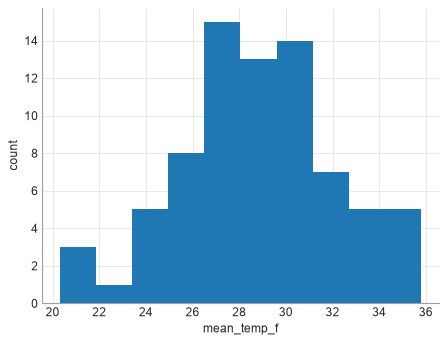

In [99]:
plt.hist(winters["mean_temp_f"])
plt.xlabel("mean_temp_f")
plt.ylabel("count")
plt.show()

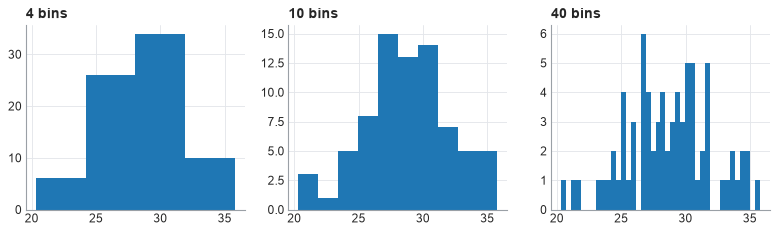

In [100]:
# How much does the choice of bins matter?  Same data, three bin counts.
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
for ax, bins in zip(axes, [4, 10, 40]):
    ax.hist(winters["mean_temp_f"], bins=bins)
    ax.set_title(f"{bins} bins")
plt.show()

**What the histogram shows:** how many winters fall in each range of average temperature.

- **Shape:** roughly bell-shaped and symmetric, centered near 29°F (mean 28.7°F, median 28.9°F).
- **Unusual values:** three very cold winters near 20–22°F (1976–77, 1962–63, 1977–78) and a small bump of very warm winters at 33–36°F. Are those the El Niño winters?
- **Effect of bins:** 4 bins merge everything into one lump; 40 bins turn the plot into noise. The default 10 is reasonable, but its edges land on awkward values, so the redesign uses 1°F bins on whole degrees.

### 2.2 Scatter plot — does a stronger El Niño go with a warmer winter?

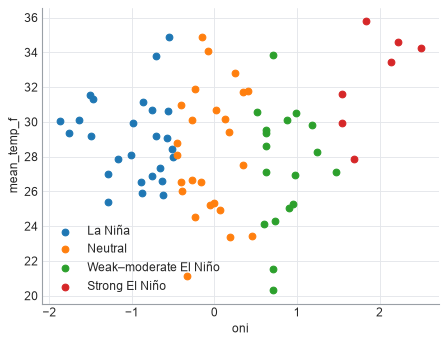

In [101]:
for group in GROUPS:
    sub = winters[winters["enso_group"] == group]
    plt.scatter(sub["oni"], sub["mean_temp_f"], label=group)
plt.xlabel("oni")
plt.ylabel("mean_temp_f")
plt.legend()
plt.show()

**What the scatter plot shows:** each dot is one winter, with the ONI on the x-axis and mean temperature on the y-axis, colored by type of winter.

There is **no straight-line pattern**; the cloud is nearly flat. But the **strong El Niño** dots on the far right sit high (6 of 7 are warmer than average), while **weak–moderate El Niño** winters have the widest spread and include the coldest winter on record. If El Niño matters for temperature, it seems to matter only once it is strong.

### 2.3 Boxplot — comparing the four kinds of winter

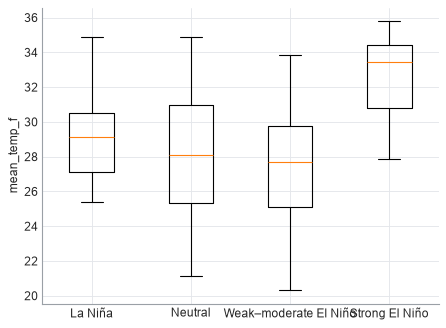

In [102]:
plt.boxplot([winters.loc[winters["enso_group"] == g, "mean_temp_f"] for g in GROUPS],
            tick_labels=GROUPS)
plt.ylabel("mean_temp_f")
plt.show()

**What the boxplot shows:** the line in each box is the group's median, the box spans the middle 50% of winters, and the whiskers show the spread.

- The **Strong El Niño** median (33.5°F) is 4–6°F above La Niña (29.1°F), Neutral (28.1°F) and Weak–moderate El Niño (27.7°F).
- The other three groups overlap almost completely.
- **Weak–moderate El Niño** has the largest spread (about 20°F to 34°F).

One caution: the strong El Niño box is drawn from only 7 winters.

## Part 3 — Redesigned visualizations

The drafts use column names as labels, colors that carry no meaning, and show only one of my three hypotheses. Below I set **one shared style** and rebuild each figure.

In [103]:
# ---- One consistent style for the whole report --------------------------------------
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 80,
    "font.size": 11,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#9aa0a6",
    "grid.color": "#e3e6ea",
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})

# One color per kind of winter, used in EVERY figure.
# Cool blue = cool Pacific, grey = nothing special, orange -> dark red = warmer Pacific.
COLORS = {"La Niña": "#3b7dd8",
          "Neutral": "#b3bac2",
          "Weak–moderate El Niño": "#f2a344",
          "Strong El Niño": "#b3261e"}
INK = "#2b2f33"      # text and reference lines
MUTED = "#6b7178"    # secondary text

# The three hypotheses, written once so every figure labels them the same way
OUTCOMES = {
    "mean_temp_f":  {"title": "Warmer?", "label": "Mean winter temperature (°F)"},
    "precip_in":    {"title": "Drier?",  "label": "Total winter precipitation (in)"},
    "sunshine_pct": {"title": "Sunnier?", "label": "Sunshine (% of daylight hours)"},
}
SUPER = [1983, 1998, 2016]   # the three "very strong" El Niño winters (ONI ≥ 2.0)
LABEL_NUDGE = {1983: 0, 1998: 7, 2016: -7}   # vertical nudge (points) so their labels do not collide

### Figure 1 — Histogram, redesigned

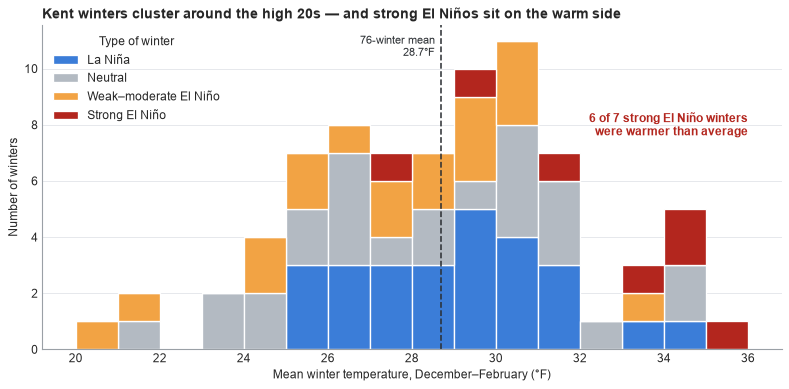

In [104]:
fig, ax = plt.subplots(figsize=(10, 5))

# 1°F-wide bins on whole-degree edges, so each bar is "winters that averaged 27-28°F", etc.
lo, hi = np.floor(winters["mean_temp_f"].min()), np.ceil(winters["mean_temp_f"].max())
bins = np.arange(lo, hi + 1, 1)

# Stack the four kinds of winter so color shows WHERE each kind falls in the distribution
ax.hist([winters.loc[winters["enso_group"] == g, "mean_temp_f"] for g in GROUPS],
        bins=bins, stacked=True, color=[COLORS[g] for g in GROUPS], label=GROUPS,
        edgecolor="white", linewidth=1.2)

mean_all = winters["mean_temp_f"].mean()
ax.axvline(mean_all, color=INK, linestyle="--", linewidth=1.4)
ax.text(mean_all - 0.15, ax.get_ylim()[1] * 0.97, f"76-winter mean\n{mean_all:.1f}°F",
        ha="right", va="top", color=INK, fontsize=10)

n_warm = (strong["mean_temp_f"] > mean_all).sum()
ax.text(hi, ax.get_ylim()[1] * 0.66,
        f"{n_warm} of {len(strong)} strong El Niño winters\nwere warmer than average",
        ha="right", color=COLORS["Strong El Niño"], fontsize=10.5, fontweight="bold")

ax.set_title("Kent winters cluster around the high 20s — and strong El Niños sit on the warm side")
ax.set_xlabel("Mean winter temperature, December–February (°F)")
ax.set_ylabel("Number of winters")
ax.set_xticks(bins[::2])
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
ax.legend(title="Type of winter", loc="upper left")
plt.tight_layout()
plt.show()

### Figure 2 — Scatter plot, redesigned: all three hypotheses side by side

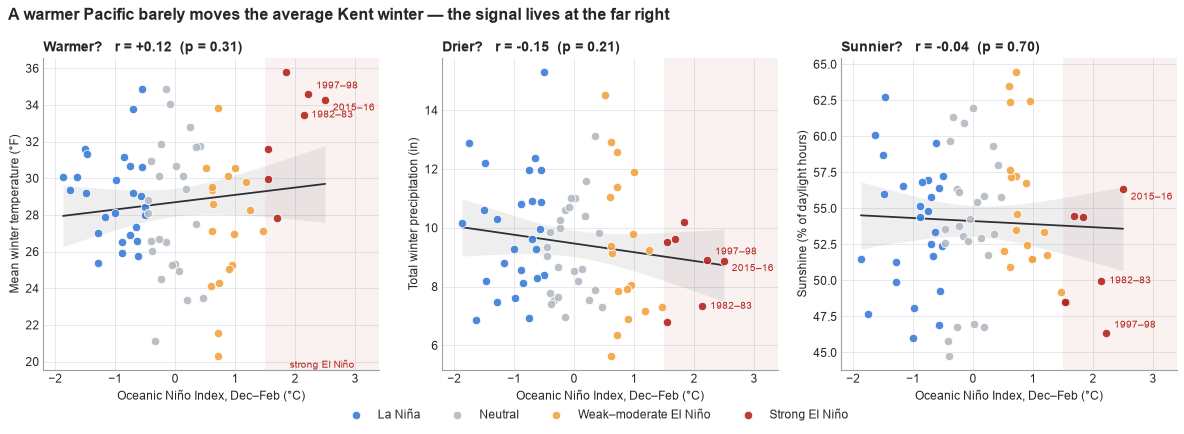

In [105]:
def add_trend_line(ax, x, y, color=INK):
    """Draw the OLS best-fit line with its 95% confidence band; return (r, p)."""
    data = pd.DataFrame({"x": x, "y": y})
    model = smf.ols("y ~ x", data=data).fit()
    grid = pd.DataFrame({"x": np.linspace(x.min(), x.max(), 100)})
    pred = model.get_prediction(grid).summary_frame(alpha=0.05)
    ax.fill_between(grid["x"], pred["mean_ci_lower"], pred["mean_ci_upper"], color=color, alpha=0.08, lw=0)
    ax.plot(grid["x"], pred["mean"], color=color, linewidth=1.6)
    return stats.pearsonr(x, y)

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))

for ax, (col, info) in zip(axes, OUTCOMES.items()):
    ax.axvspan(1.5, 3.4, color=COLORS["Strong El Niño"], alpha=0.06, lw=0)   # the "strong" zone
    for group in GROUPS:
        sub = winters[winters["enso_group"] == group]
        ax.scatter(sub["oni"], sub[col], s=58, color=COLORS[group], alpha=0.9,
                   edgecolor="white", linewidth=0.8, label=group, zorder=3)
    r, p = add_trend_line(ax, winters["oni"], winters[col])

    # Name the three "super" El Niño winters so readers can follow them across panels
    for _, row in winters[winters["winter"].isin(SUPER)].iterrows():
        ax.annotate(row["label"], (row["oni"], row[col]), xytext=(7, LABEL_NUDGE[row["winter"]]),
                    textcoords="offset points", ha="left", va="center", fontsize=9,
                    color=COLORS["Strong El Niño"])

    ax.set_title(f"{info['title']}   r = {r:+.2f}  (p = {p:.2f})")
    ax.set_xlabel("Oceanic Niño Index, Dec–Feb (°C)")
    ax.set_ylabel(info["label"])
    ax.set_xlim(-2.2, 3.4)

axes[0].text(2.45, axes[0].get_ylim()[0], "strong El Niño", ha="center", va="bottom",
             fontsize=9, color=COLORS["Strong El Niño"])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("A warmer Pacific barely moves the average Kent winter — the signal lives at the far right",
             x=0.01, ha="left", fontsize=14.5, fontweight="bold")
plt.tight_layout()
plt.show()

### Figure 3 — Boxplot, redesigned

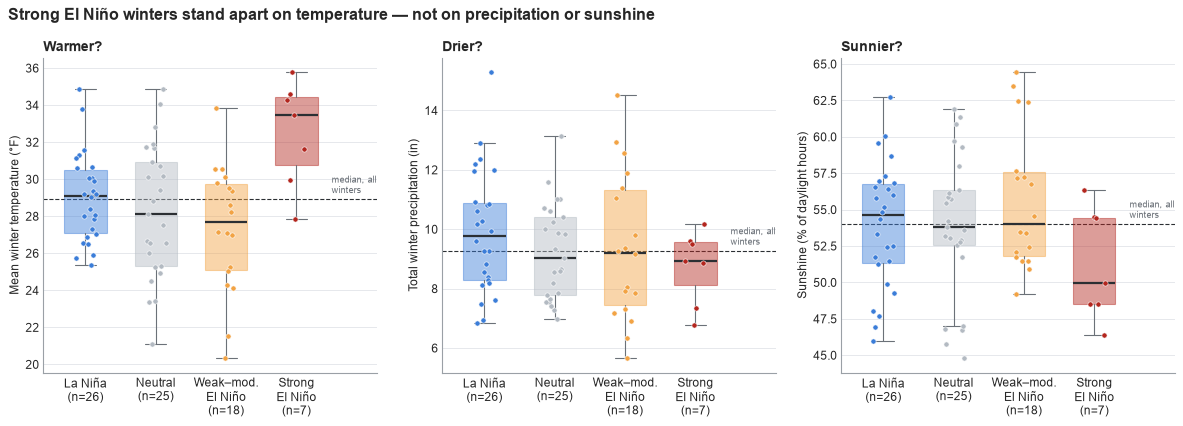

In [106]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
rng = np.random.default_rng(42)                     # fixed seed so the jitter is repeatable
short = ["La Niña", "Neutral", "Weak–mod.\nEl Niño", "Strong\nEl Niño"]
counts = winters["enso_group"].value_counts()

for ax, (col, info) in zip(axes, OUTCOMES.items()):
    groups = [winters.loc[winters["enso_group"] == g, col] for g in GROUPS]
    box = ax.boxplot(groups, patch_artist=True, widths=0.6, showfliers=False,
                     medianprops=dict(color=INK, linewidth=2),
                     whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, g in zip(box["boxes"], GROUPS):
        patch.set(facecolor=COLORS[g], alpha=0.45, edgecolor=COLORS[g])

    # Show every winter as a dot: with only 7 strong events the raw points matter
    for i, (vals, g) in enumerate(zip(groups, GROUPS), start=1):
        ax.scatter(i + rng.uniform(-0.16, 0.16, len(vals)), vals, s=22, color=COLORS[g],
                   edgecolor="white", linewidth=0.5, zorder=3)

    median_all = winters[col].median()
    ax.axhline(median_all, color=INK, linestyle="--", linewidth=1, zorder=1)
    ax.annotate("median, all\nwinters", (4.5, median_all), xytext=(0, 3), textcoords="offset points",
                fontsize=8.5, color=MUTED, va="bottom")

    ax.set_title(info["title"])
    ax.set_ylabel(info["label"])
    ax.set_xticks(range(1, 5), [f"{s}\n(n={counts[g]})" for s, g in zip(short, GROUPS)])
    ax.set_xlim(0.4, 5.15)
    ax.grid(axis="x", visible=False)

fig.suptitle("Strong El Niño winters stand apart on temperature — not on precipitation or sunshine",
             x=0.01, ha="left", fontsize=14.5, fontweight="bold")
plt.tight_layout()
plt.show()

### Figure 4 (extra) — 76 winters on one timeline

Putting the winters in order shows something the other figures cannot: a slow background warming that the statistics need to account for.

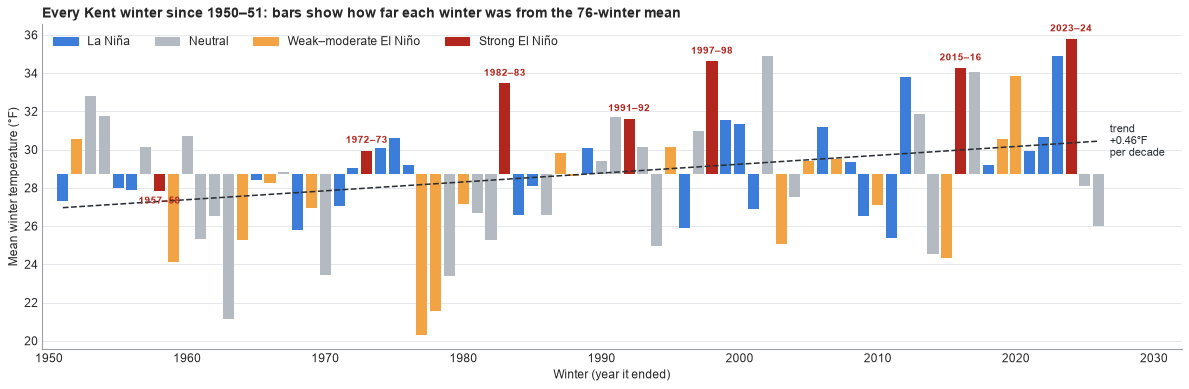

In [107]:
fig, ax = plt.subplots(figsize=(15, 5))

baseline = winters["mean_temp_f"].mean()
ax.bar(winters["winter"], winters["mean_temp_f"] - baseline, bottom=baseline, width=0.8,
       color=[COLORS[g] for g in winters["enso_group"]])

# Long-term linear trend
slope, intercept = np.polyfit(winters["winter"], winters["mean_temp_f"], 1)
ax.plot(winters["winter"], intercept + slope * winters["winter"], color=INK, linestyle="--", linewidth=1.4)
ax.text(winters["winter"].max() + 0.8, intercept + slope * winters["winter"].max(),
        f"trend\n{slope * 10:+.2f}°F\nper decade", va="center", fontsize=9.5, color=INK)

for _, row in strong.iterrows():
    above = row["mean_temp_f"] >= baseline
    ax.annotate(row["label"], (row["winter"], row["mean_temp_f"]), xytext=(0, 5 if above else -5),
                textcoords="offset points", ha="center", va="bottom" if above else "top",
                fontsize=9, fontweight="bold", color=COLORS["Strong El Niño"])

ax.set_title("Every Kent winter since 1950–51: bars show how far each winter was from the 76-winter mean")
ax.set_xlabel("Winter (year it ended)")
ax.set_ylabel("Mean winter temperature (°F)")
ax.set_xlim(1949.5, winters["winter"].max() + 6)
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[g]) for g in GROUPS], labels=GROUPS,
          ncol=4, loc="upper left")
plt.tight_layout()
plt.show()

### Figure 5 (extra) — A report card for each strong El Niño

There are only seven strong events, so this figure grades each one separately. Each cell shows how far that winter was from the long-term trend, in standard deviations. **Green supports my hypothesis; purple contradicts it.**

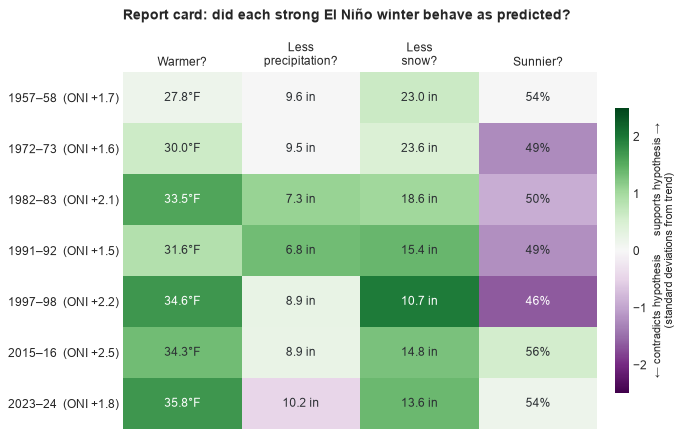

Strong El Niño winters on the 'supports' side, out of 7
Warmer?                7
Less precipitation?    5
Less snow?             7
Sunnier?               2


In [108]:
def detrended_z(series, years):
    """z-score of each winter relative to the straight-line trend through all winters."""
    resid = series - np.polyval(np.polyfit(years, series, 1), years)
    return resid / resid.std()

card_cols = {"mean_temp_f": ("Warmer?", +1, "{:.1f}°F"),
             "precip_in": ("Less\nprecipitation?", -1, "{:.1f} in"),
             "snowfall_in": ("Less\nsnow?", -1, "{:.1f} in"),
             "sunshine_pct": ("Sunnier?", +1, "{:.0f}%")}

z = pd.DataFrame({col: sign * detrended_z(winters[col], winters["winter"])
                  for col, (_, sign, _) in card_cols.items()})
z_strong = z[winters["strong_el_nino"] == 1]

fig, ax = plt.subplots(figsize=(9, 5.6))
im = ax.imshow(z_strong.values, cmap="PRGn", vmin=-2.5, vmax=2.5, aspect="auto")

for i, idx in enumerate(z_strong.index):
    for j, (col, (_, _, fmt)) in enumerate(card_cols.items()):
        score = z_strong.iloc[i, j]
        ax.text(j, i, fmt.format(winters.loc[idx, col]), ha="center", va="center", fontsize=10.5,
                color="white" if abs(score) > 1.5 else INK)

ax.set_xticks(range(len(card_cols)), [t for t, _, _ in card_cols.values()])
ax.set_yticks(range(len(z_strong)),
              [f"{winters.loc[i, 'label']}  (ONI {winters.loc[i, 'oni']:+.1f})" for i in z_strong.index])
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.03)
cbar.set_label("← contradicts hypothesis      supports hypothesis →\n(standard deviations from trend)", fontsize=9.5)
cbar.outline.set_visible(False)
ax.set_title("Report card: did each strong El Niño winter behave as predicted?\n", loc="left")
plt.tight_layout()
plt.show()

support = (z_strong > 0).sum()
print("Strong El Niño winters on the 'supports' side, out of", len(z_strong))
print(support.rename({c: v[0].replace("\n", " ") for c, v in card_cols.items()}).to_string())

### Design decisions

| What I changed | Why it helps the reader |
|---|---|
| **One style sheet and shared settings** (`plt.style.use`, `rcParams`): top/right spines removed, light gridlines | Every figure follows the same rules, and the data stands out from the frame. |
| **One meaningful color per type of winter** in every figure | Blue = cool Pacific, grey = neutral, orange to dark red = warm Pacific, so a strong El Niño can be followed from chart to chart. |
| **Titles that state the finding; axis labels with units** | The reader knows what to look for before reading the axes. |
| **Histogram: 1°F bins on whole degrees, stacked by winter type** | Each bar has a plain meaning, and the stacking shows where strong El Niños fall. |
| **Subplots with all three hypotheses side by side** | Warmer, drier and sunnier can be compared in one glance. |
| **Reference lines, a regression line with a 95% confidence band, and annotations** naming the three biggest El Niños | Shows what "normal" is, how uncertain the slope is, and which dots are the winters people remember. |
| **Raw points over the boxplots, with group sizes** | Shows how little data sits behind the strong El Niño box. |

## Part 4 — Statistical analysis

My hypothesis has two parts, so I use both options:

- **Option B (relationship):** does the ONI correlate with each weather variable?
- **Option A (two groups):** do strong El Niño winters differ from all other winters?

### 4.1 Option B — Correlation with the Oceanic Niño Index

In [109]:
all_outcomes = {"mean_temp_f": "Mean temperature (°F)", "precip_in": "Precipitation (in)",
                "snowfall_in": "Snowfall (in)", "sunshine_pct": "Sunshine (% of daylight)",
                "cloud_cover_pct": "Cloud cover (%)"}

rows = []
for col, name in all_outcomes.items():
    r, p = stats.pearsonr(winters["oni"], winters[col])
    rho, p_rho = stats.spearmanr(winters["oni"], winters[col])
    rows.append({"Outcome": name, "Pearson r": r, "p-value": p, "r²": r ** 2,
                 "Spearman ρ": rho, "p-value (ρ)": p_rho})
corr_table = pd.DataFrame(rows).set_index("Outcome").round(3)
corr_table

,Pearson r,p-value,r²,Spearman ρ,p-value (ρ)
Outcome,,,,,
Mean temperature (°F),0.117,0.314,0.014,0.050,0.667
Precipitation (in),-0.147,0.205,0.022,-0.147,0.206
Snowfall (in),-0.237,0.040,0.056,-0.210,0.068
Sunshine (% of daylight),-0.045,0.701,0.002,-0.025,0.830
Cloud cover (%),-0.034,0.771,0.001,-0.021,0.855


**OLS regression.** Y = mean winter temperature; X = Dec–Feb ONI. Figure 4 showed a warming trend, and several big El Niños are recent, so I add time (`decades`) as a second X variable to keep the trend from being credited to El Niño.

In [110]:
winters["decades"] = (winters["winter"] - winters["winter"].min()) / 10   # decades since the first winter

model_b = smf.ols("mean_temp_f ~ oni + decades", data=winters).fit()
print(model_b.summary().tables[1])
print(f"\nR² = {model_b.rsquared:.3f}   (n = {int(model_b.nobs)} winters)")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     26.9452      0.730     36.932      0.000      25.491      28.399
oni            0.4130      0.377      1.094      0.278      -0.339       1.165
decades        0.4663      0.168      2.777      0.007       0.132       0.801

R² = 0.108   (n = 76 winters)


### 4.2 Option A — Strong El Niño winters vs. every other winter

Y = each weather variable in turn; X = `strong_el_nino` (1 = ONI ≥ 1.5, 0 = otherwise), plus the trend term. The `strong_el_nino` coefficient is the average difference between the two groups.

In [111]:
model_a = smf.ols("mean_temp_f ~ strong_el_nino + decades", data=winters).fit()
print(model_a.summary().tables[1])
print(f"\nR² = {model_a.rsquared:.3f}")

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         26.6921      0.689     38.738      0.000      25.319      28.065
strong_el_nino     4.0207      1.197      3.360      0.001       1.636       6.405
decades            0.4370      0.158      2.771      0.007       0.123       0.751

R² = 0.215


In [112]:
# The same two-group model for every outcome, collected into one table
rows = []
for col, name in all_outcomes.items():
    m = smf.ols(f"{col} ~ strong_el_nino + decades", data=winters).fit()
    lo, hi = m.conf_int().loc["strong_el_nino"]
    rows.append({"Outcome": name,
                 "Other winters (mean)": winters.loc[winters["strong_el_nino"] == 0, col].mean(),
                 "Strong El Niño (mean)": winters.loc[winters["strong_el_nino"] == 1, col].mean(),
                 "Difference (trend-adjusted)": m.params["strong_el_nino"],
                 "95% CI low": lo, "95% CI high": hi,
                 "p-value": m.pvalues["strong_el_nino"]})
group_table = pd.DataFrame(rows).set_index("Outcome").round(3)
group_table

,Other winters (mean),Strong El Niño (mean),Difference (trend-adjusted),95% CI low,95% CI high,p-value
Outcome,,,,,,
Mean temperature (°F),28.315,32.505,4.021,1.636,6.405,0.001
Precipitation (in),9.532,8.745,-0.771,-2.348,0.805,0.333
Snowfall (in),27.072,17.096,-9.780,-15.446,-4.114,0.001
Sunshine (% of daylight),54.406,51.229,-3.133,-6.789,0.523,0.092
Cloud cover (%),76.977,77.693,0.610,-2.007,3.227,0.644


### 4.3 Does strength matter among El Niño winters?

The ONI barely correlates with temperature, yet strong El Niño winters are clearly warmer. To see why, I look only at El Niño winters (ONI ≥ +0.5).

In [113]:
el_nino = winters[winters["oni"] >= 0.5]
rows = []
for col, name in all_outcomes.items():
    m = smf.ols(f"{col} ~ oni", data=el_nino).fit()
    r, p = stats.pearsonr(el_nino["oni"], el_nino[col])
    rows.append({"Outcome": name, "Change per +1°C of ONI": m.params["oni"], "Pearson r": r, "p-value": p})
print(f"El Niño winters only (n = {len(el_nino)})")
pd.DataFrame(rows).set_index("Outcome").round(3)

El Niño winters only (n = 25)


,Change per +1°C of ONI,Pearson r,p-value
Outcome,,,
Mean temperature (°F),4.180,0.603,0.001
Precipitation (in),-0.972,-0.251,0.226
Snowfall (in),-8.427,-0.550,0.004
Sunshine (% of daylight),-4.049,-0.476,0.016
Cloud cover (%),1.787,0.307,0.136


### What the statistics show

**Option B (all 76 winters).** The correlations with the ONI are all weak: temperature r = +0.12, precipitation r = −0.15, sunshine r = −0.04. Only snowfall reaches p < 0.05 (r = −0.24). In the regression the ONI is not significant (p = 0.28), but the trend is: about **+0.47°F per decade** (p = 0.007).

**Option A (strong El Niño vs. other winters, trend-adjusted).** Strong El Niño winters were:

- **4.0°F warmer** (95% CI 1.6 to 6.4°F, p = 0.001)
- **9.8 inches less snowy** (p = 0.001)
- 0.8 inches lower in total precipitation, not significant (p = 0.33)
- 3.1 percentage points *less* sunny, not significant (p = 0.09)

**Why the two disagree (4.3).** A correlation measures a straight-line relationship, and this one is flat until El Niño is strong, then rises steeply. Among the 25 El Niño winters, temperature rises with the ONI (r = +0.60, p = 0.001) and sunshine falls (r = −0.48, p = 0.02).

| | Hypothesis | Verdict |
|---|---|---|
| H1 | Warmer | **Supported for strong El Niños only.** |
| H2 | Drier | **Partly.** Much less snow, but total precipitation is not reliably lower. |
| H3 | Sunnier | **Not supported.** Stronger El Niño winters were, if anything, cloudier. |

**Limitations and assumptions**

- **Correlation, not causation.**
- **Small group:** only 7 strong El Niño winters, so one unusual winter can move the estimates.
- **OLS assumes** a straight-line relationship, independent observations and roughly normal residuals. The straight-line assumption fails for the ONI across all winters, which is why Option A is more informative here.
- **Many tests:** I tested five outcomes. At a stricter threshold (p < 0.01) the temperature and snowfall differences still hold.
- **Section 4.3 was chosen after seeing the data**, so its p-values are descriptive.
- **The 1.5°C cut-off for "strong"** is a convention; another cut-off would move winters between groups.

## Part 5 — Conclusions and reflection

**What I learned.** Across 76 Kent winters, my hypothesis was about one third right.

- **Warmer: yes, but only when El Niño is strong.** Strong El Niño winters averaged about 4°F warmer after accounting for the long-term trend. Weak and moderate El Niños showed no warming; the coldest winter on record, 1976–77, was a weak El Niño.
- **Drier: only as less snow.** Strong El Niño winters had about 10 inches less snowfall, but total precipitation was not reliably lower.
- **Sunnier: no.** There is no relationship overall, and among El Niño winters the stronger ones were cloudier.

So H1 is supported for strong events only, H2 for snowfall only, and H3 is not supported.

**Most effective visualization.** Figure 3, the redesigned boxplot. It shows all three hypotheses with the same four groups: the strong El Niño box jumps up for temperature, barely moves for precipitation, and drops for sunshine. The dots also show how few strong events there are.

**What the statistics revealed that the plots did not.**

1. *The warming trend is a confounder.* Several strong El Niños are recent, so without the trend term I could not separate "El Niño" from "recent". The 4°F difference holds after the adjustment.
2. *The correlation alone was misleading.* r = +0.12 suggests El Niño does not matter for temperature; the group comparison shows it matters a lot, but only at the strong end.
3. *The precipitation difference is not real evidence.* It looks drier in the boxplot, but 0.8 inches is well within chance.

**Limitations and what the analysis fails to capture.**

- **The weather data is a reanalysis (a weather model constrained by observations), not station measurements.** In a separate check against instruments at Cleveland Hopkins Airport (not included here), its winter sunshine was far too high (56% against a measured 30%), so sunshine is the least certain of my three results. The measured record did agree that strong El Niño winters are not sunnier.
- **Only seven strong El Niño winters.**
- **One number per winter** hides cold snaps and big storms, and total precipitation does not separate rain from ice.
- **Correlation only.**

**What would improve it.** Station and satellite observations in place of modelled sunshine and snowfall, and more time: each new strong El Niño adds to a very small sample, starting with this winter.